Cell 1 — Imports and Paths

In [1]:
import os
import io
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import ipywidgets as widgets

from PIL import Image
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


Cell 2 — Project Paths

In [2]:
# ==============================
# PROJECT PATHS
# ==============================

project_path = r"E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Datasetz\Datasetzz\Screenshot_Phishing_Project"

dataset_path = os.path.join(
    project_path,
    "dataset",
    "FINAL_DATASET_1_3"
)

model_path = os.path.join(
    project_path,
    "models",
    "mobilenetv2_final_finetuned.keras"
)

results_path = os.path.join(
    project_path,
    "results"
)

print("Dataset path:", dataset_path)
print("Model path:", model_path)

print("\nDataset exists:", os.path.exists(dataset_path))
print("Model exists:", os.path.exists(model_path))

Dataset path: E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Datasetz\Datasetzz\Screenshot_Phishing_Project\dataset\FINAL_DATASET_1_3
Model path: E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Datasetz\Datasetzz\Screenshot_Phishing_Project\models\mobilenetv2_final_finetuned.keras

Dataset exists: True
Model exists: True


Cell 3 — Dataset Information

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Dataset:", "FINAL_DATASET_1_3")

Image Size: (224, 224)
Batch Size: 32
Dataset: FINAL_DATASET_1_3


Cell 4 — Load Training Dataset

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

print("\nClasses:", train_ds.class_names)

Found 8256 files belonging to 2 classes.
Using 6605 files for training.

Classes: ['legitimate', 'phishing']


Cell 5 — Load Validation Dataset

In [5]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

print("\nClasses:", val_ds.class_names)

Found 8256 files belonging to 2 classes.
Using 1651 files for validation.

Classes: ['legitimate', 'phishing']


Cell 6 — Optimize Dataset Loading

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Dataset preparation completed.")

Dataset preparation completed.


Cell 7 — Dataset Count

In [7]:
legitimate_count = 2064
phishing_count = 6192
total_count = legitimate_count + phishing_count

print("================================")
print("FINAL DATASET")
print("================================")
print(f"Legitimate images : {legitimate_count}")
print(f"Phishing images   : {phishing_count}")
print(f"Total images      : {total_count}")
print("Ratio             : 1 : 3")

FINAL DATASET
Legitimate images : 2064
Phishing images   : 6192
Total images      : 8256
Ratio             : 1 : 3


Cell 8 — Load Final Model

In [8]:
final_model = tf.keras.models.load_model(model_path)

print("Final model loaded successfully!")
print("Total parameters:", final_model.count_params())

Final model loaded successfully!
Total parameters: 2259265


Cell 9 — Model Summary

In [9]:
final_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,314,629 (20.27 MB)

 Trainable params: 1,527,681 (5.83 MB)

 Non-trainable params: 731,584 (2.79 MB)

 Optimizer params: 3,055,364 (11.66 MB)

Cell 10 — Validation Evaluation

In [10]:
validation_loss, validation_accuracy = final_model.evaluate(
    val_ds,
    verbose=1
)

print("\n================================")
print("VALIDATION RESULTS")
print("================================")
print(f"Validation Loss: {validation_loss:.4f}")
print(f"Validation Accuracy: {validation_accuracy * 100:.2f}%")

52/52 ━━━━━━━━━━━━━━━━━━━━ 59s 948ms/step - accuracy: 0.8795 - loss: 0.2938

VALIDATION RESULTS
Validation Loss: 0.2938
Validation Accuracy: 87.95%


Cell 11 — Collect Validation Predictions

In [11]:
true_labels = []
all_predictions = []

for images, labels in val_ds:

    predictions = final_model.predict(
        images,
        verbose=0
    ).flatten()

    all_predictions.extend(predictions)
    true_labels.extend(labels.numpy().flatten())

true_labels = np.array(true_labels)
all_predictions = np.array(all_predictions)

print("Validation predictions collected.")
print("Total predictions:", len(all_predictions))

Validation predictions collected.
Total predictions: 1651


Cell 12 — Final Threshold

In [12]:
THRESHOLD = 0.60

predicted_labels = (
    all_predictions >= THRESHOLD
).astype(int)

print("Decision Threshold:", THRESHOLD)

Decision Threshold: 0.6


Cell 13 — Validation Classification Report

In [13]:
print("================================")
print("CLASSIFICATION REPORT")
print("================================")

print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=["LEGITIMATE", "PHISHING"],
        digits=4
    )
)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  LEGITIMATE     0.6612    0.8438    0.7414       384
    PHISHING     0.9483    0.8690    0.9069      1267

    accuracy                         0.8631      1651
   macro avg     0.8048    0.8564    0.8242      1651
weighted avg     0.8815    0.8631    0.8684      1651



Cell 14 — Validation Confusion Matrix

In [14]:
cm = confusion_matrix(
    true_labels,
    predicted_labels
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 324   60]
 [ 166 1101]]


Cell 15 — Confusion Matrix Graph

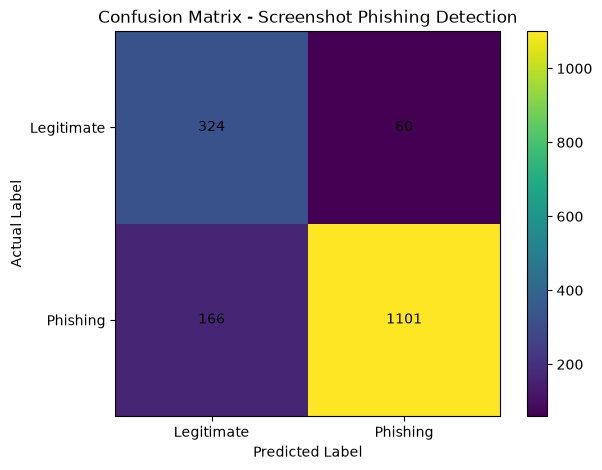

In [15]:
plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Confusion Matrix - Screenshot Phishing Detection")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Legitimate", "Phishing"]
)

plt.yticks(
    [0, 1],
    ["Legitimate", "Phishing"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

Cell 16 — ROC Curve and AUC

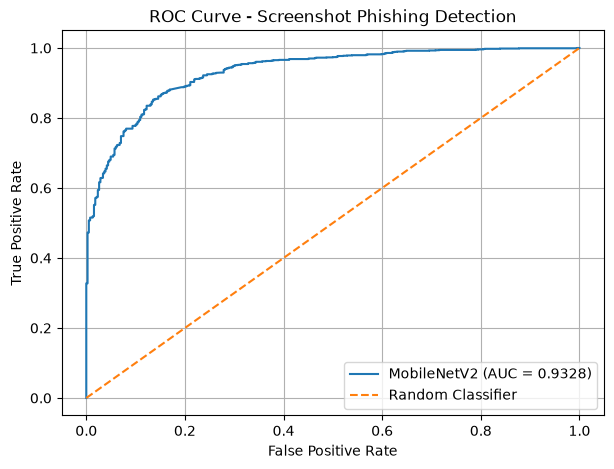

AUC Score: 0.9328


In [16]:
fpr, tpr, thresholds = roc_curve(
    true_labels,
    all_predictions
)

roc_auc = auc(
    fpr,
    tpr
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"MobileNetV2 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Screenshot Phishing Detection"
)

plt.legend()
plt.grid(True)

plt.show()

print(f"AUC Score: {roc_auc:.4f}")

Cell 17 — Final Results Table

In [17]:
import pandas as pd

results = {
    "Metric": [
        "Training Dataset",
        "Total Dataset Images",
        "Legitimate Images",
        "Phishing Images",
        "Model",
        "Best Validation Accuracy",
        "Test-Subset Accuracy",
        "Legitimate Precision",
        "Legitimate Recall",
        "Legitimate F1-Score",
        "Phishing Precision",
        "Phishing Recall",
        "Phishing F1-Score",
        "ROC-AUC",
        "Decision Threshold"
    ],

    "Result": [
        "FINAL_DATASET_1_3",
        "8,256",
        "2,064",
        "6,192",
        "MobileNetV2 + Fine-Tuning",
        "87.95%",
        "90.06%",
        "75.62%",
        "88.83%",
        "81.70%",
        "96.05%",
        "90.47%",
        "93.18%",
        "0.9641",
        "0.60"
    ]
}

results_df = pd.DataFrame(results)

display(results_df)

,Metric,Result
0,Training Dataset,FINAL_DATASET_1_3
1,Total Dataset Images,"8,256"
2,Legitimate Images,"2,064"
3,Phishing Images,"6,192"
4,Model,MobileNetV2 + Fine-Tuning
5,Best Validation Accuracy,87.95%
6,Test-Subset Accuracy,90.06%
7,Legitimate Precision,75.62%
8,Legitimate Recall,88.83%
9,Legitimate F1-Score,81.70%


Cell 18 — Single Screenshot Prediction

This is your main real-world prediction section.

Run this before your screenshot uploader code:

In [18]:
import ipywidgets as widgets
from IPython.display import display, clear_output

In [19]:
upload = widgets.FileUpload(
    accept="image/*",
    multiple=False
)

predict_button = widgets.Button(
    description="🔍 Predict Screenshot",
    button_style="success"
)

output = widgets.Output()

Cell 19 — Original Class + Prediction

This is the updated version you wanted.

In [20]:
original_class = widgets.Dropdown(
    options=["PHISHING", "LEGITIMATE"],
    value="PHISHING",
    description="Original:"
)

Cell 20 — Prediction Function

In [21]:
def predict_screenshot(button):

    with output:

        output.clear_output()

        if len(upload.value) == 0:
            print("Please upload a screenshot first.")
            return

        uploaded_file = upload.value[0]

        filename = uploaded_file["name"]
        image_data = uploaded_file["content"]

        image = Image.open(
            io.BytesIO(image_data)
        ).convert("RGB")

        image = image.resize(
            (224, 224)
        )

        image_array = np.array(
            image,
            dtype=np.float32
        )

        image_array = np.expand_dims(
            image_array,
            axis=0
        )

        prediction = final_model.predict(
            image_array,
            verbose=0
        )[0][0]

        # Model classification
        if prediction >= THRESHOLD:

            predicted_class = "PHISHING"
            confidence = prediction * 100

        else:

            predicted_class = "LEGITIMATE"
            confidence = (1 - prediction) * 100

        # Original class
        actual_class = original_class.value

        # Compare
        if actual_class == predicted_class:

            result = "CORRECT ✅"

        else:

            result = "INCORRECT ❌"

        print("================================")
        print("SCREENSHOT PHISHING DETECTION")
        print("================================")

        print(f"File:       {filename}")
        print(f"Original:   {actual_class}")
        print(f"Prediction: {predicted_class}")
        print(f"Confidence: {confidence:.2f}%")
        print(f"Result:     {result}")
        print(f"Threshold:  {THRESHOLD}")

        print("================================")

Cell 21 — Display Single PredictionTool

Cell 21A — Imports

In [22]:
import io
import numpy as np
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

Cell 21B — Create a fresh prediction tool

In [23]:
# Fresh widgets — replaces the old button/output

upload_single = widgets.FileUpload(
    accept="image/*",
    multiple=False
)

original_class_single = widgets.Dropdown(
    options=["PHISHING", "LEGITIMATE"],
    value="PHISHING",
    description="Original:"
)

predict_single_button = widgets.Button(
    description="🔍 Predict Screenshot",
    button_style="success"
)

output_single = widgets.Output()

Cell 21C — Prediction function

In [24]:
def predict_screenshot_single(button):

    with output_single:
        clear_output()

        # Screenshot prediction threshold
        threshold = 0.60

        # Check upload
        if not upload_single.value:
            print("⚠️ Please upload a screenshot first.")
            return

        # Get uploaded file
        uploaded_data = upload_single.value

        # Support newer and older ipywidgets versions
        if isinstance(uploaded_data, tuple):
            uploaded_file = uploaded_data[0]
        else:
            uploaded_file = list(uploaded_data.values())[0]

        image_bytes = uploaded_file["content"]

        # Open image
        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        # Resize
        image = image.resize((224, 224))

        # Convert to NumPy
        image_array = np.array(
            image,
            dtype=np.float32
        )

        # Add batch dimension
        image_array = np.expand_dims(
            image_array,
            axis=0
        )

        # Model prediction
        probability = final_model.predict(
            image_array,
            verbose=0
        )[0][0]

        # Apply threshold
        if probability >= threshold:
            predicted_class = "PHISHING"
            confidence = probability * 100
        else:
            predicted_class = "LEGITIMATE"
            confidence = (1 - probability) * 100

        # Original class selected by user
        actual_class = original_class_single.value

        # Compare
        if actual_class == predicted_class:
            result = "CORRECT ✅"
        else:
            result = "INCORRECT ❌"

        # Display result
        print("=" * 50)
        print("       SCREENSHOT PHISHING DETECTION")
        print("=" * 50)

        print(f"\nOriginal   : {actual_class}")
        print(f"Prediction : {predicted_class}")
        print(f"Confidence : {confidence:.2f}%")
        print(f"Result     : {result}")

        print("\n" + "=" * 50)

Cell 21D — Connect and display

In [25]:
predict_single_button.on_click(
    predict_screenshot_single
)

display(upload_single)
display(original_class_single)
display(predict_single_button)
display(output_single)

FileUpload(value=(), accept='image/*', description='Upload')

Dropdown(description='Original:', options=('PHISHING', 'LEGITIMATE'), value='PHISHING')

Button(button_style='success', description='🔍 Predict Screenshot', style=ButtonStyle())

Output()

Cell 22 - Multiple Screenshot

In [26]:
multi_upload = widgets.FileUpload(
    accept="image/*",
    multiple=True
)

multi_predict_button = widgets.Button(
    description="🔍 Predict All Screenshots",
    button_style="success"
)

multi_output = widgets.Output()

Cell 23 — Multiple Prediction Function

In [27]:
def predict_multiple_screenshots(button):

    with multi_output:

        multi_output.clear_output()

        if len(multi_upload.value) == 0:
            print("Please upload screenshots first.")
            return

        print("==============================================")
        print("     SCREENSHOT PHISHING DETECTION")
        print("==============================================")

        print(f"Total screenshots: {len(multi_upload.value)}")
        print(f"Threshold: {THRESHOLD}")

        print("==============================================\n")

        phishing_count = 0
        legitimate_count = 0

        for i, uploaded_file in enumerate(
            multi_upload.value,
            start=1
        ):

            filename = uploaded_file["name"]

            image_data = uploaded_file["content"]

            image = Image.open(
                io.BytesIO(image_data)
            ).convert("RGB")

            image = image.resize(
                (224, 224)
            )

            image_array = np.array(
                image,
                dtype=np.float32
            )

            image_array = np.expand_dims(
                image_array,
                axis=0
            )

            prediction = final_model.predict(
                image_array,
                verbose=0
            )[0][0]

            if prediction >= THRESHOLD:

                predicted_class = "PHISHING"
                confidence = prediction * 100
                phishing_count += 1

            else:

                predicted_class = "LEGITIMATE"
                confidence = (1 - prediction) * 100
                legitimate_count += 1

            print(f"{i}. {filename}")
            print(f"   Prediction : {predicted_class}")
            print(f"   Confidence: {confidence:.2f}%")
            print("----------------------------------------------")

        print("\n==============================================")
        print("                 SUMMARY")
        print("==============================================")

        print(
            f"Total screenshots : {len(multi_upload.value)}"
        )

        print(
            f"Phishing          : {phishing_count}"
        )

        print(
            f"Legitimate        : {legitimate_count}"
        )

        print("==============================================")

Cell 24 — Display Multiple Prediction Tool

In [28]:
multi_predict_button.on_click(
    predict_multiple_screenshots
)

display(multi_upload)
display(multi_predict_button)
display(multi_output)

FileUpload(value=(), accept='image/*', description='Upload', multiple=True)

Button(button_style='success', description='🔍 Predict All Screenshots', style=ButtonStyle())

Output()

Cell 25 — Save Final Results

In [29]:
import os

# Screenshot project results folder
results_path = r"E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Datasetz\Datasetzz\Screenshot_Phishing_Project\results"

# Create results folder if it does not exist
os.makedirs(results_path, exist_ok=True)

final_results_text = """
SCREENSHOT PHISHING DETECTION
=============================

Dataset:
FINAL_DATASET_1_3

Dataset Size:
8,256 images

Legitimate:
2,064 images

Phishing:
6,192 images

Model:
MobileNetV2 + Fine-Tuning

Best Validation Accuracy:
87.95%

Post-Hoc Test-Subset Accuracy:
90.06%

Legitimate Precision:
75.62%

Legitimate Recall:
88.83%

Legitimate F1-Score:
81.70%

Phishing Precision:
96.05%

Phishing Recall:
90.47%

Phishing F1-Score:
93.18%

ROC-AUC:
0.9641

Decision Threshold:
0.60

Final Model:
mobilenetv2_final_finetuned.keras

Important Note:
The 825-image test subset was created after model
training from FINAL_DATASET_1_3. Therefore it is a
post-hoc diagnostic test subset and should not be
described as a completely independent unseen test set.
"""

# Save results
final_results_path = os.path.join(
    results_path,
    "final_project_results.txt"
)

with open(
    final_results_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(final_results_text)

print("Final results saved successfully!")
print("Location:")
print(final_results_path)

Final results saved successfully!
Location:
E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Datasetz\Datasetzz\Screenshot_Phishing_Project\results\final_project_results.txt
